# Ordinal relations need asymmetric query-key interactions
**Task.** Items have a latent order $A < B < C < \dots$. The model sees two one-hot items $(x_1, x_2)$ and must output 1 if $x_1 < x_2$ and 0 if $x_1 > x_2$.

**Model.** The smallest attention-style model is a single query-key score:
$$
s(x_1, x_2) = \frac{(W_q x_2)^\top (W_k x_1)}{\sqrt{d}} = \frac{x_1^\top M x_2}{\sqrt{d}}, \qquad M = W_k^\top W_q .
$$
With one-hot inputs, the logit for the pair (item $i$, item $j$) is just the entry $M_{ij}$.

**Claim.** Split $M$ into symmetric and antisymmetric parts, $M = S + A$ with $S = \tfrac{1}{2}(M + M^\top)$ and $A = \tfrac{1}{2}(M - M^\top)$. The pair $(i, j)$ and its reversal $(j, i)$ always have opposite labels, but $S$ gives them the *same* logit $S_{ij} = S_{ji}$. Only $A$, for which $A_{ij} = -A_{ji}$, can tell them apart. So an ordinal relation can only be represented by the antisymmetric part of the query-key interaction.

**Consequence.** Models that tie queries and keys together, $W_q = W_k = W$ (as in CoRelNet), have $M = W^\top W$, which is symmetric, so $A = 0$. Each pair and its reversal get the same logit, so they cannot beat chance **regardless of size**. (On a finite training set, the two directions of a pair are not sampled exactly equally, so the best a symmetric model can do is predict the more frequent direction of each pair. We compute this ceiling below.)

This notebook checks the claim empirically. All models are trained on **every** pair, so the question is what each model can represent, not how it generalizes.

## Imports

In [1]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import seaborn as sns
import string
from collections import Counter

from relational_attention.tasks import OrdinalRelationsDataset
from relational_attention.models import QueryKeyScorer, CoRelNet
from relational_attention.training import train_model, evaluate_model

In [2]:
torch.manual_seed(0)

## The task

In [3]:
# Parameters
num_samples = 1000
num_items = 10
letters = list(string.ascii_uppercase[:num_items])

In [4]:
dataset = OrdinalRelationsDataset(num_samples=num_samples, num_items=num_items, pairs='all')
loader = DataLoader(dataset, batch_size=16, shuffle=True)

In [5]:
x, y = dataset[0]
print(x)
print(f'{letters[x[0].argmax()]} < {letters[x[1].argmax()]} ?  label = {int(y)}')

tensor([[0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.]])
C < E ?  label = 1


In [6]:
# Best accuracy and loss achievable by ANY symmetric model on this training set:
# a symmetric model gives (i, j) and (j, i) the same logit, so the best it can do
# is predict the empirical frequency of the forward direction for each unordered pair.
counts = Counter((int(x[0].argmax()), int(x[1].argmax())) for x, _ in dataset)
ceiling_acc, ceiling_loss = 0, 0
for (i, j), n in counts.items():
    if i < j:
        m = counts.get((j, i), 0)
        p = n / (n + m)
        ceiling_acc += max(n, m)
        ceiling_loss -= n * np.log(p) + m * np.log(1 - p) if 0 < p < 1 else 0
ceiling_acc /= len(dataset)
ceiling_loss /= len(dataset)
print(f'Symmetric model ceiling: accuracy {ceiling_acc:.3f}, loss {ceiling_loss:.4f}')

Symmetric model ceiling: accuracy 0.565, loss 0.6790


## Train both models
`QueryKeyScorer` has separate query and key matrices with only a 2-dimensional head. `CoRelNet` shares one matrix, and we give it a 10-dimensional head, so it has far *more* capacity.

In [7]:
lr = 1e-3
loss_fn = torch.nn.BCEWithLogitsLoss()
epochs = 500

In [8]:
models = {
    'Separate $W_q, W_k$ (d=2)': QueryKeyScorer(embed_dim=num_items, head_dim=2),
    'Shared $W$, CoRelNet (d=10)': CoRelNet(embed_dim=num_items, head_dim=num_items),
}

losses = {}
for name, model in models.items():
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses[name] = train_model(model, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs, verbose=False)
    print(f'{name:30s} final loss {losses[name][-1]:.4f}   accuracy {evaluate_model(model, loader):.3f}')

Separate $W_q, W_k$ (d=2)      final loss 0.0000   accuracy 1.000


Shared $W$, CoRelNet (d=10)    final loss 0.6802   accuracy 0.564


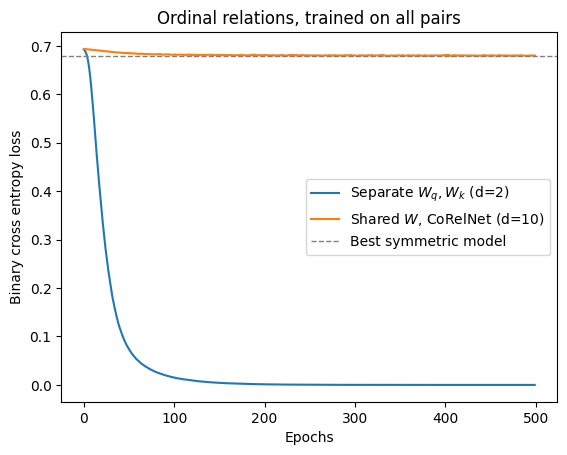

In [9]:
for name, loss in losses.items():
    plt.plot(loss, label=name)
plt.axhline(ceiling_loss, color='gray', linestyle='--', linewidth=1, label='Best symmetric model')

plt.xlabel('Epochs')
plt.ylabel('Binary cross entropy loss')
plt.title('Ordinal relations, trained on all pairs')
plt.legend()
plt.show()

## The learned query-key matrices
For each model we plot $M$ and its symmetric and antisymmetric parts. Entry $(i, j)$ is the logit for the pair (first item $i$, second item $j$); a perfect solution is positive above the diagonal and negative below it.

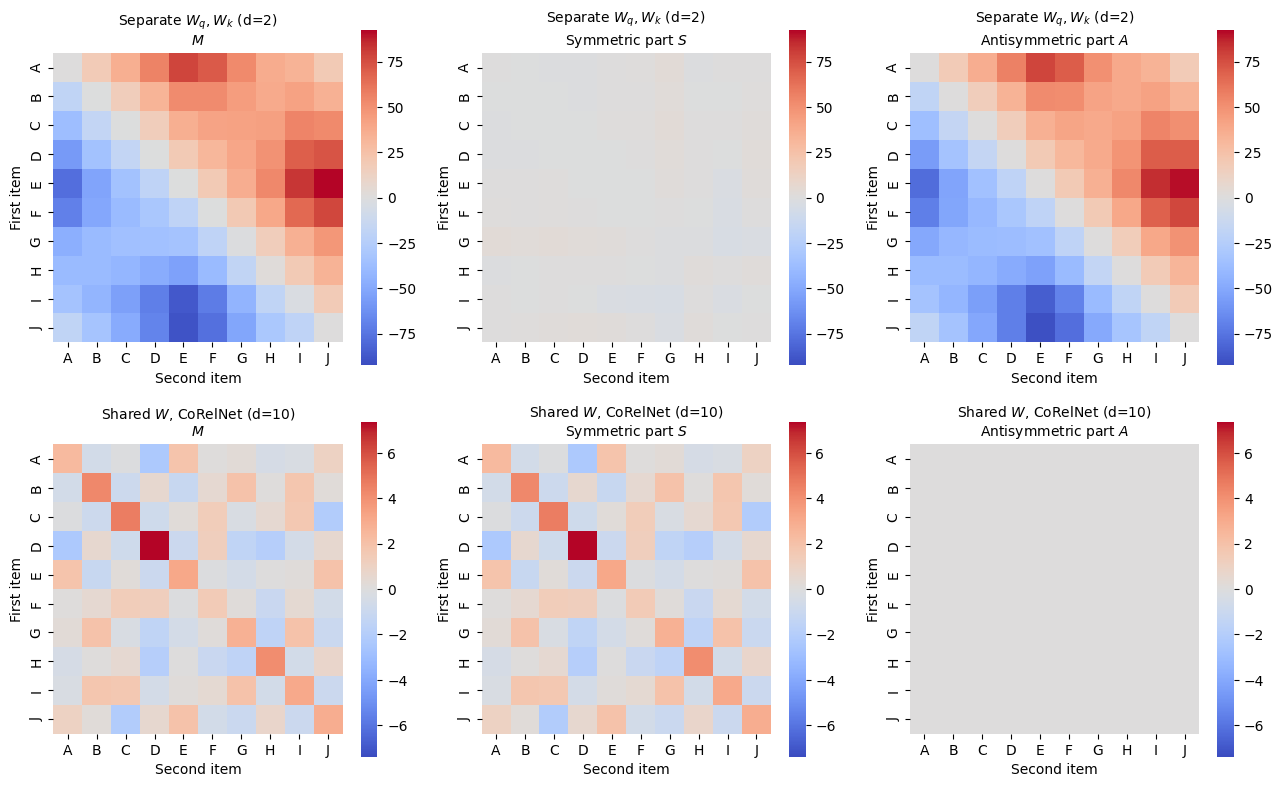

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
with torch.no_grad():
    for row, (name, model) in zip(axes, models.items()):
        M = model.query_key_matrix()
        parts = {'$M$': M, 'Symmetric part $S$': (M + M.T) / 2, 'Antisymmetric part $A$': (M - M.T) / 2}
        lim = M.abs().max()
        for ax, (title, P) in zip(row, parts.items()):
            sns.heatmap(P, cmap='coolwarm', center=0, vmin=-lim, vmax=lim, ax=ax,
                        xticklabels=letters, yticklabels=letters, square=True)
            ax.set_title(f'{name}\n{title}', fontsize=10)
            ax.set_xlabel('Second item')
            ax.set_ylabel('First item')
plt.tight_layout()
plt.show()

## Across 30 seeds
`scripts/ordinal_relations_batch.py` repeats the comparison from 30 random initializations (run it from the repo root). *Antisymmetry* is $\|A\|_F / (\|A\|_F + \|S\|_F)$: 1 for a purely antisymmetric $M$, 0 for a purely symmetric one.

In [11]:
results = pd.read_csv('../data/ordinal_relations_results.csv')
results.groupby('model')[['final_loss', 'accuracy', 'antisymmetry']].agg(['mean', 'min', 'max'])

final_loss                             accuracy                \
                   mean           min           max     mean    min    max   
model                                                                        
corelnet   6.796772e-01  6.788382e-01  6.809715e-01   0.5643  0.563  0.565   
query_key  4.677583e-07  2.607023e-07  6.160465e-07   1.0000  1.000  1.000   

          antisymmetry                     
                  mean      min       max  
model                                      
corelnet      0.000000  0.00000  0.000000  
query_key     0.953797  0.91513  0.977399

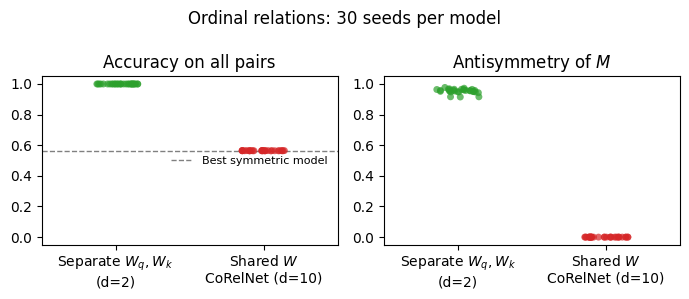

In [12]:
names = {'query_key': 'Separate $W_q, W_k$\n(d=2)', 'corelnet': 'Shared $W$\nCoRelNet (d=10)'}
results['Model'] = results['model'].map(names)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, (column, title) in zip(axes, [('accuracy', 'Accuracy on all pairs'), ('antisymmetry', 'Antisymmetry of $M$')]):
    sns.stripplot(data=results, x='Model', y=column, hue='Model', palette=['tab:green', 'tab:red'],
                  order=list(names.values()), alpha=0.7, jitter=0.15, legend=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_ylim(-0.05, 1.05)
axes[0].axhline(ceiling_acc, color='gray', linestyle='--', linewidth=1, label='Best symmetric model')
axes[0].legend(fontsize=8, frameon=False, loc='center right')
plt.suptitle('Ordinal relations: 30 seeds per model')
plt.tight_layout()
plt.savefig('../results/ordinal_relations_asymmetry.svg', bbox_inches='tight')
plt.show()